![](https://images.thedirect.com/media/article_full/transformers-rise-of-the-beasts-runtime.jpg)

# Agenda

1. 什么是深度学习？
    - 深度学习架构
    - 分类问题与损失函数
    - 梯度下降
    - 数据处理
    - 线性层/全连接层
    - MLP

2. 关于大语言模型我们要了解什么？
    - RNN / seq2seq
    - attention / transformer
    - BERT / GPT
    - llama / alpaca
    - GLM
   
3. 将大语言模型运用于工作的思考与尝试。

# 深度学习架构

深度学习的整体流程如图所示：

![](pic/深度学习流程.png)

1. 数据集分为训练集、验证集和测试集。训练集用以训练深度学习模型；验证集用以评估模型结果，进而辅助模型调参；测试集用以模型的预测。一般而言，训练集、验证集与测试集的比例为7:2:1。

2. 训练集、验证集 用于模型的训练

3. 测试数据集 用于模型的推理。

# 分类问题与损失函数

深度学习处理的问题大部分都是分类问题。
例如一张照片里的动物是猫、狗还是人？


![](pic/cat.jpg)

In [1]:
import torch
import torch.nn.functional as F

# 我们可以把 这个问题看成一个概率分布
# 说明：这个确定的概率分布一般被称为 targets，中文称为标签。这也是数据打标的由来
t1 = torch.tensor([1, 0, 0], dtype=torch.float16)  # 代表图片为猫
t2 = torch.tensor([0, 1, 0], dtype=torch.float16)  # 代表图片为狗
t3 = torch.tensor([0, 0, 1], dtype=torch.float16)  # 代表图片为人

In [2]:
# 图片输入 ->  神经网络 -> 输出一个长度与分类数量相同的向量 这个向量一般被称为 logits

# 假设通过神经网络 之后的输出是  1.7614, 0.1982, 0.0432
logits = torch.tensor([1.7614, 0.1982, 0.0432])
logits

tensor([1.7614, 0.1982, 0.0432])

In [4]:
# 通过Softmax 可以将值计算成概率分布，方便与targets 进行比较。
# 通过  Softmax 函数的转换，值的大小关系不发生改变。

output = F.softmax(logits, dim=-1)
print(output)
output.sum(dim=-1)

tensor([0.7200, 0.1508, 0.1292])


tensor(1.)

In [5]:
# 损失函数 交叉熵 用于表示两个概率分布的相似程度。值越低，表示两个概率分布约相似。
# pytorch 提供的 cross_entropy 里面包含了Softmax

loss = F.cross_entropy(logits, t1)
loss

tensor(0.3285)

In [6]:
logits1 = torch.tensor([2.7614, 0.1982, 0.432])
logits2 = torch.tensor([27.614, 1.982, 4.32])  # 将 logits1 中的值放大10倍
r1 = F.cross_entropy(logits1, t1)
r2 = F.cross_entropy(logits2, t1)
r1, r2

(tensor(0.1608), tensor(-0.))

总结：


1. 深度学习处理的问题大部分都是分类问题

2. 神经网络的输出值需要与分类数量相同（logits），然后使用 SoftMax算法可以将神经网络的输出转化成一个概率分布

3. 交叉熵可以比较两个概率分布的相似度，相似度称为loss。

4. 深度学习的过程是让loss值不断变小的过程。

## 梯度下降

- 深度学习在学什么？

- 我们如何让我们的 loss 值减少？深度学习到底在学什么？

![](pic/梯度下降.png)


1. 找到loss 的最小值，即找到整个损失函数的最小值。对于简单的函数可以通过求导的方式找到解析解。

2. 深度学习中使用一种名为梯度下降（gradient descent）的方法， 这种方法几乎可以优化所有深度学习模型。 它通过不断地在损失函数递减的方向上更新参数来降低误差。


3. 梯度下降的计算方式：

  - 根据设计好的模型，系统会构建一个计算图（computational graph）， 来跟踪计算是哪些数据通过哪些操作组合起来产生输出。 

  - 自动微分使系统能够随后反向传播梯度。 这里，反向传播（backpropagate）意味着跟踪整个计算图，填充关于每个参数的偏导数。

In [7]:
import torch
x = torch.arange(4.0, requires_grad=True)
x

tensor([0., 1., 2., 3.], requires_grad=True)

In [8]:
y = 2 * torch.dot(x, x)
y

tensor(28., grad_fn=<MulBackward0>)

In [9]:
y.backward()
x.grad

tensor([ 0.,  4.,  8., 12.])

## 数据处理

- 训练数据集 / 验证数据集 / 测试数据集

- 将数据转换成 向量（张量）

- 获取数据集的 targets用于计算 loss

In [1]:
# 图像分类数据集

# MNIST数据集 (LeCun et al., 1998) 是图像分类中广泛使用的数据集之一，但作为基准数据集过于简单。
# 我们将使用类似但更复杂的Fashion-MNIST数据集 (Xiao et al., 2017)。

import torch
import torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

In [2]:
# 读取数据
trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(
    root="../data", train=True, transform=trans, download=True)  # 训练数据集
mnist_test = torchvision.datasets.FashionMNIST(
    root="../data", train=False, transform=trans, download=True)  # 测试数据集
len(mnist_train), len(mnist_test)

(60000, 10000)

In [3]:
mnist_train[1000][0].shape, mnist_train[1000][1]

# 1. 每张图片形状 是 28 * 28
# 2. 第二个int 类型的数据代表图片的分类

(torch.Size([1, 28, 28]), 1)

In [4]:
# 读取小批量
batch_size = 16


def get_dataloader_workers():  # @save
    """使用4个进程来读取数据"""
    return 4


train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True,
                             num_workers=get_dataloader_workers())


def get_fashion_mnist_labels(labels):  # @save
    """返回Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat',
                   'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

torch.Size([16, 1, 28, 28]) torch.float32 torch.Size([16]) torch.int64
tensor([7, 1, 4, 5, 2, 5, 0, 4, 4, 5, 7, 8, 9, 7, 0, 0])


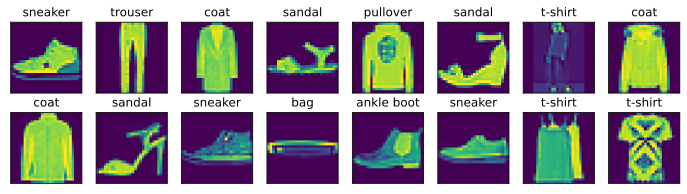

In [5]:
for x, y in train_iter:
    print(x.shape, x.dtype, y.shape, y.dtype)
    print(y)
    d2l.show_images(x.reshape(16, 28, 28), 2, 8,
                    titles=get_fashion_mnist_labels(y))
    break

## linear - 线性层/全连接层

![](https://zh-v2.d2l.ai/_images/softmaxreg.svg)

1. 输入矩阵为 (1 * m) 的矩阵， 输出是一个 (1, n) 的矩阵
2. 中的 W 为一个 (m * n) 的矩阵, b 是一个 (1, n) 的矩阵
3. o=𝐗𝐰+𝑏

In [22]:
# 每张图片是 28 * 28 的大小，所以输入层是 784。
# 数据集中有 10类图片， 输出层的大小是 10.

import torch
from torch import nn
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

In [23]:
# PyTorch不会隐式地调整输入的形状。因此，是用nn.Flatten() 将28 * 28 变成784 长度的向量
# 我们在线性层前定义了展平层（flatten），来调整网络输入的形状

net = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))


def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)


net.apply(init_weights)

In [24]:
# Softmax + 交叉熵 作为损失函数
loss = nn.CrossEntropyLoss(reduction='none')

# 使用随机梯度下降
trainer = torch.optim.SGD(net.parameters(), lr=0.1)

In [25]:
def train_epoch(net, train_iter, loss, updater):
    net.train()
    metric = Accumulator(3)

    for X, y in train_iter:
        # 计算梯度并更新参数
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            # 使用PyTorch内置的优化器和损失函数
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        metric.add(float(l.sum()), accuracy(y_hat, y), y.numel())
    # 返回训练损失和训练精度
    return metric[0] / metric[2], metric[1] / metric[2]

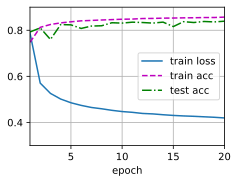

In [26]:
# 开始训练
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):  # @save
    """训练模型"""
    animator = Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9],
                        legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        train_metrics = train_epoch(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))
    train_loss, train_acc = train_metrics
    assert train_loss < 0.5, train_loss
    assert train_acc <= 1 and train_acc > 0.7, train_acc
    assert test_acc <= 1 and test_acc > 0.7, test_acc


num_epochs = 20
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)

In [ ]:
# 进行预测
def predict(net, test_iter, n=10):  # @save
    """预测标签（定义见第3章）"""
    for X, y in test_iter:
        break
    trues = d2l.get_fashion_mnist_labels(y)
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
    titles = [true + '\n' + pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[0:n].reshape((n, 28, 28)), 1, 10, titles=titles[0:n])


predict(net, test_iter)

总结：

1. 通过 linear 层，我们可以将输出层 输出的元素数量与分类的类别数量保持一致。

2. 借助softmax 和交叉熵，我们可以训练多分类的模型。

2. 多数常见的深度学习模型都有类似的训练过程：先读取数据，再定义模型和损失函数，然后使用优化算法训练模型。




##  多层感知机-MLP 

![](https://zh-v2.d2l.ai/_images/mlp.svg)

1. 线性意味着单调假设： 任何特征的增大都会导致模型输出的增大（如果对应的权重为正）， 或者导致模型输出的减小（如果对应的权重为负）

2. 我们可以通过在网络中加入一个或多个隐藏层来克服线性模型的限制， 使其能处理更普遍的函数关系类型。 要做到这一点，最简单的方法是将许多全连接层堆叠在一起。 每一层都输出到上面的层，直到生成最后的输出。 我们可以把前层看作表示，把最后一层看作线性预测器。 这种架构通常称为多层感知机（multilayer perceptron），通常缩写为MLP。 下面，我们以图的方式描述了多层感知机

### 激活函数

1. 简单的将两个或者多个全连接层叠加在一起，等价于一个全连接层。 

2. 需要在每一个隐藏层使用非线性的激活函数，确保多层感知机不会退化成线性模型。

3. 常见激活函数
  - ReLU函数
  - sigmoid
  - tanh函数

https://zh-v2.d2l.ai/chapter_multilayer-perceptrons/mlp.html#id6


### MLP 实现

In [29]:
import torch
from torch import nn
from d2l import torch as d2l

train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)


# 定义超参
hidden_width = 256
lr = 0.1

# 定义训练变量
batch_size, num_epochs = 256, 20

net = nn.Sequential(nn.Flatten(),
                    nn.Linear(784, hidden_width),
                    nn.ReLU(),
                    nn.Linear(hidden_width, 10))


def init_weights(m):
    if type(m) == nn.Linear:
        nn.init.normal_(m.weight, std=0.01)


net.apply(init_weights)

loss = nn.CrossEntropyLoss(reduction='none')
trainer = torch.optim.SGD(net.parameters(), lr=lr)

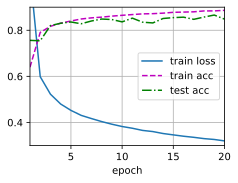

In [30]:
d2l.train_ch3(net, train_iter, test_iter, loss, num_epochs, trainer)